In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.special import erf
import sys

In [3]:
def read_data(file_path,sheet_name,namex):
    data = pd.read_excel(file_path, sheet_name=sheet_name)  
    data = data[["Total", "Voltage"]].dropna()
    x = data[namex].to_numpy(dtype=float)
    V = data["Voltage"].to_numpy(dtype=float)
    order = np.argsort(x)
    return x[order], V[order]

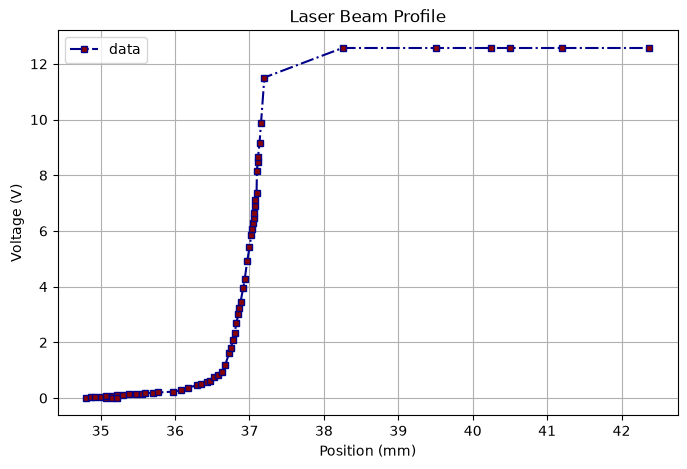

In [4]:
# laser beam profile
x, V = read_data("DATA.csv", "Sheet1", "Total")
#plot the data
plt.figure(figsize=(8, 5))
plt.plot(x, V,marker='s',markersize=5,linestyle='-.',markerfacecolor='darkred',color='darkblue', label="data")
plt.xlabel("Position (mm)")
plt.ylabel("Voltage (V)")
plt.title("Laser Beam Profile")
plt.grid()
plt.legend()
plt.show()

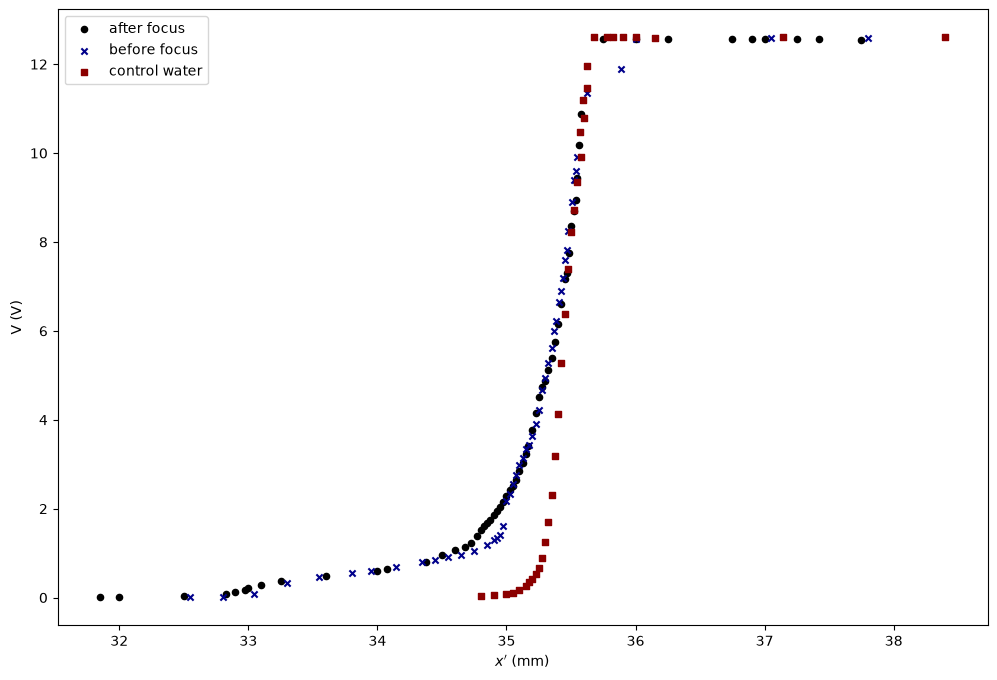

In [5]:
# data of sample before and after focus, also control water 
x1,V1 = read_data("DATA.csv","Sheet2","Total") # after focus
x2,V2 = read_data("DATA.csv","Sheet3","Total") # before focus
x3,V3 = read_data("DATA.csv","Sheet4","Total") # control water
x,V = read_data("DATA.csv","Sheet1","Total") # laser beam profile
x2 = x2 + 0.3 # offset for better visualization
x3 = x3 + 0.9# offset for better visualization
# # # plotting the data
plt.figure(figsize=(12, 8))
plt.scatter(x1, V1, marker='o', s=20, color='black', label="after focus")
plt.scatter(x2, V2, marker='x', s=20, color='darkblue', label="before focus")
plt.scatter(x3, V3, marker='s', s=20, color='darkred', label="control water")
# plt.plot(x, V, marker='o', markersize=5, linestyle='-', color = 'darkgreen',label="laser beam profile")
# plt.plot(x1, V1, marker='o', markersize=5, linestyle='-.', color = 'black',label="after focus")
# plt.plot(x2, V2, marker='x', markersize=5, linestyle='--', color = 'darkblue',label="before focus")
# plt.plot(x3, V3, marker='s', markersize=5, linestyle='-', color = 'darkred',label="control water")
plt.xlabel(r"$x'$ (mm)")
plt.ylabel(r"V (V)")
plt.legend()
plt.show()


V0 (V)   = 0.2540 +/- 0.0727
A (V)    = 12.4243 +/- 0.1674
x0 (mm)  = 37.0319 +/- 0.0056
w (mm)   = 0.3146 +/- 0.0120
Fit equation: V(x) = (0.254 ± 0.073) + 0.5 * (12.424 ± 0.167) * (1 + erf((x - (37.032 ± 0.006)) / (0.315 ± 0.012)))
w from 8%/92% points = 0.3458 mm


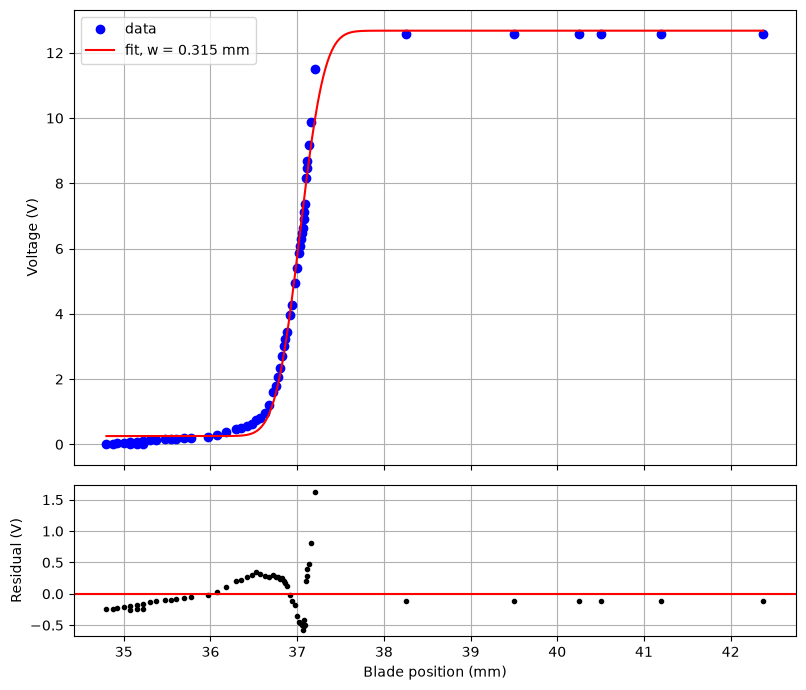

In [52]:
data = pd.read_excel("DATA.csv", sheet_name="Sheet1")  
data = data[["Total", "Voltage"]].dropna()
x = data["Total"].to_numpy(dtype=float)
V = data["Voltage"].to_numpy(dtype=float)

order = np.argsort(x)
x, V = x[order], V[order]

# Fit function ((paper's Eq. 11))
def model(x, V0, A, x0, w):
    return V0 + 0.5 * A * (1 + erf((x - x0) / w))

# Fit: Initial guesses 
V0_g = float(V.min())
A_g = float(V.max() - V.min())
x0_g = float(x[np.argmin(np.abs(V - (V0_g + A_g / 2)))])
p0 = [V0_g, A_g, x0_g, 0.3]

popt, pcov = curve_fit(model, x, V, p0=p0)
perr = np.sqrt(np.diag(pcov))
names = ["V0 (V)", "A (V)", "x0 (mm)", "w (mm)"]
for n, v, e in zip(names, popt, perr):
    print(f"{n:8s} = {v:.4f} +/- {e:.4f}")

eqn = f"V(x) = ({popt[0]:.3f} ± {perr[0]:.3f}) + 0.5 * ({popt[1]:.3f} ± {perr[1]:.3f}) * (1 + erf((x - ({popt[2]:.3f} ± {perr[2]:.3f})) / ({popt[3]:.3f} ± {perr[3]:.3f})))" # with errors 
print(f"Fit equation: {eqn}")
# ---- 4. Cross-check: paper's 8% / 92% method ----
Vn = (V - popt[0]) / popt[1]
x8 = np.interp(0.08, Vn, x)
x92 = np.interp(0.92, Vn, x)
print(f"w from 8%/92% points = {(x92 - x8) / 2:.4f} mm")

# ---- 5. Plots: fit and residuals ----
xf = np.linspace(x.min(), x.max(), 1000)
fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(x, V, "bo", label="data")
ax[0].plot(xf, model(xf, *popt), "r-", label=f"fit, w = {popt[3]:.3f} mm")
ax[0].set_ylabel("Voltage (V)"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(x, V - model(x, *popt), "k.")
ax[1].axhline(0, color="r"); ax[1].set_ylabel("Residual (V)")
ax[1].set_xlabel("Blade position (mm)"); ax[1].grid(True)
plt.tight_layout(); plt.show()